# My Notebook: Predicting Medical Insurance Costs
**Question:** How well can we predict someone's yearly insurance charges from their age, sex, BMI, children, smoking and region — and can we beat the basic linear regression?

I follow the same flow as the original (load → explore → preprocess → split → train → evaluate → residuals), with my own code and explanations.

**My improvements:**
1. **Duplicate check** (the original only checked for missing values).
2. **Better EDA:** plots that show *why* smokers cost so much, and how smoking and BMI interact.
3. **An evaluation function** that reports R², RMSE, MAE and 5-fold cross-validation for any model.
4. **Feature engineering:** new columns `obese`, `smoker_obese` and `age²` — the improvement the original suggested but never tried.
5. **A second model type:** Random Forest, compared side by side.
6. **Predicted vs. actual plot** to see the improvement visually.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")

## 1. Load the data

In [2]:
url = "https://raw.githubusercontent.com/duochen/data-science-bootcamp/refs/heads/main/Data/insurance.csv"
ins = pd.read_csv(url)
print(ins.shape)
ins.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Improvement #1: check for missing values *and* duplicates

In [3]:
print("Missing values per column:\n", ins.isna().sum(), sep="")
print("\nDuplicate rows:", ins.duplicated().sum())
print(ins[ins.duplicated(keep=False)])

ins = ins.drop_duplicates().reset_index(drop=True)
print("\nRows after removing duplicates:", len(ins))

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1
     age   sex    bmi  children smoker     region    charges
195   19  male  30.59         0     no  northwest  1639.5631
581   19  male  30.59         0     no  northwest  1639.5631

Rows after removing duplicates: 1337


There are no missing values, but there is **one exact duplicate** (two identical 19-year-old men). Duplicates can end up in both the training and the test set, which makes the test score look better than it really is, so I remove it.

## 3. Improvement #2: exploring *why* charges vary

In [4]:
print("Skew of charges:", round(ins["charges"].skew(), 2))
ins.groupby("smoker")["charges"].agg(["count", "mean", "median"]).round(0)

Skew of charges: 1.52


,count,mean,median
smoker,,,
no,1063,8441.0,7346.0
yes,274,32050.0,34456.0


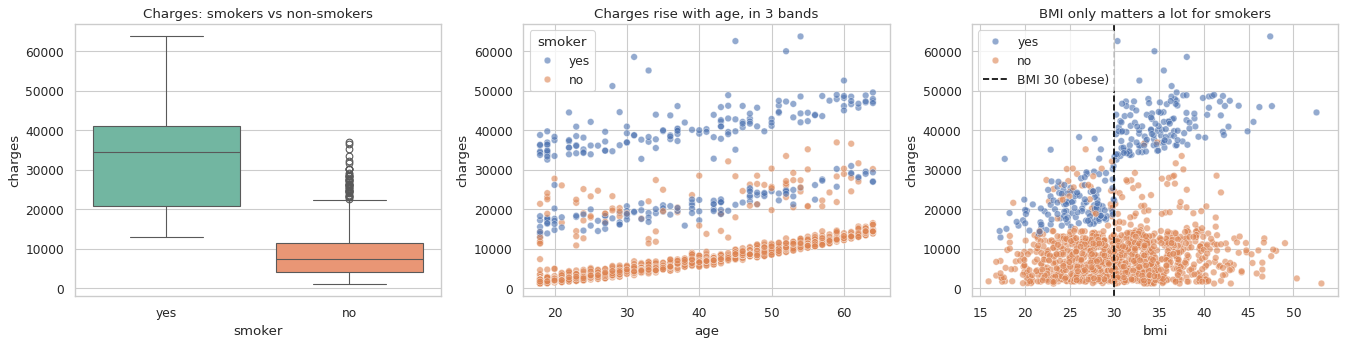

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.boxplot(data=ins, x="smoker", y="charges", hue="smoker", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Charges: smokers vs non-smokers")

sns.scatterplot(data=ins, x="age", y="charges", hue="smoker", alpha=0.6, ax=axes[1])
axes[1].set_title("Charges rise with age, in 3 bands")

sns.scatterplot(data=ins, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=axes[2])
axes[2].axvline(30, color="black", linestyle="--", label="BMI 30 (obese)")
axes[2].legend()
axes[2].set_title("BMI only matters a lot for smokers")

plt.tight_layout()
plt.show()

Three big findings:
- Smokers pay about **4× more** on average (about \$32,000 vs \$8,400).
- Charges vs age forms **three separate bands**, all rising with age.
- For **smokers**, crossing **BMI 30** (obese) makes charges jump by roughly \$20,000. For non-smokers, BMI hardly matters.

A plain linear regression can't capture "BMI matters only if you smoke", so I'll build features for it.

## 4. Preprocessing

In [6]:
df = ins.copy()
df["sex"] = (df["sex"] == "male").astype(int)        # male = 1, female = 0
df["smoker"] = (df["smoker"] == "yes").astype(int)   # yes = 1, no = 0
df = pd.get_dummies(df, columns=["region"], drop_first=True, dtype=int)  # northeast = baseline

base_features = ["age", "sex", "bmi", "children", "smoker",
                 "region_northwest", "region_southeast", "region_southwest"]
y = df["charges"]
df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


## 5. Improvement #3: one function to evaluate any model
A single train/test split can be lucky or unlucky. **5-fold cross-validation** trains and tests the model 5 times on different slices of the data and averages the R², which is more trustworthy.

In [7]:
def evaluate(model, features, name):
    """Train on 80%, test on 20%, plus 5-fold cross-validation. Returns a dict of scores."""
    X = df[features]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    cv = cross_val_score(model, X, y, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
    return {
        "Model": name,
        "Test R²": round(r2_score(y_te, pred), 3),
        "RMSE ($)": round(np.sqrt(mean_squared_error(y_te, pred))),
        "MAE ($)": round(mean_absolute_error(y_te, pred)),
        "CV R² (5-fold)": round(cv.mean(), 3),
        "_pred": pred, "_actual": y_te, "_model": model,
    }

results = [evaluate(LinearRegression(), base_features, "1. Linear (original features)")]
pd.DataFrame(results).drop(columns=["_pred", "_actual", "_model"])

,Model,Test R²,RMSE ($),MAE ($),CV R² (5-fold)
0,1. Linear (original features),0.807,5956,4177,0.739


This is the same model as the original notebook. The test R² is a bit different from the original's 0.78 because I removed the duplicate, which changes the random split. The **cross-validated R² (about 0.74)** is the more honest number.

## 6. Improvement #4: feature engineering
Based on the EDA, I add three new columns:
- `obese` = 1 if BMI ≥ 30
- `smoker_obese` = 1 only if the person smokes **and** is obese (the interaction the original suggested)
- `age2` = age², because charges rise a little faster at older ages

In [8]:
df["obese"] = (df["bmi"] >= 30).astype(int)
df["smoker_obese"] = df["smoker"] * df["obese"]
df["age2"] = df["age"] ** 2

eng_features = base_features + ["obese", "smoker_obese", "age2"]
results.append(evaluate(LinearRegression(), eng_features, "2. Linear + new features"))

# see what the new model learned
lin2 = results[-1]["_model"]
pd.Series(lin2.coef_, index=eng_features).round(0).sort_values(ascending=False)

smoker_obese        19597.0
smoker              13199.0
children              739.0
bmi                    84.0
age2                    4.0
age                   -81.0
region_northwest     -158.0
sex                  -482.0
region_southeast     -578.0
obese                -631.0
region_southwest    -1074.0
dtype: float64

The `smoker_obese` coefficient is about **\$19,600**: a smoker who is also obese pays about that much *on top of* the regular smoking cost. That one feature captures the jump we saw in the BMI plot.

## 7. Improvement #5: try a Random Forest
A Random Forest is a different kind of model: it builds hundreds of decision trees and averages them, so it can find interactions by itself without me engineering them.

In [9]:
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)
results.append(evaluate(rf, base_features, "3. Random Forest (original features)"))

summary = pd.DataFrame(results).drop(columns=["_pred", "_actual", "_model"]).set_index("Model")
summary

,Test R²,RMSE ($),MAE ($),CV R² (5-fold)
Model,,,,
1. Linear (original features),0.807,5956,4177,0.739
2. Linear + new features,0.906,4158,2394,0.861
3. Random Forest (original features),0.898,4330,2452,0.852


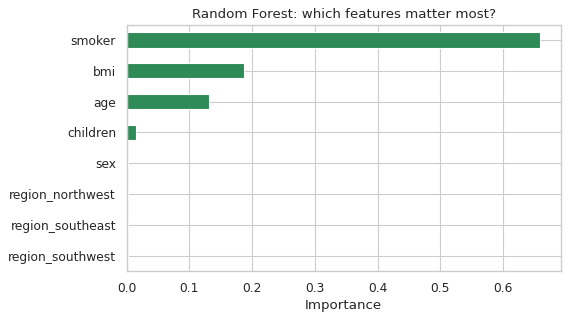

In [10]:
importances = pd.Series(rf.feature_importances_, index=base_features).sort_values()
importances.plot(kind="barh", figsize=(7, 4), color="seagreen")
plt.title("Random Forest: which features matter most?")
plt.xlabel("Importance")
plt.show()

**Comparison:**
- Adding the three engineered features raises cross-validated R² from about **0.74 to 0.86**, and cuts the typical error (RMSE) by about **\$1,800** (from about \$5,960 to \$4,160). The average error (MAE) drops by almost half.
- The Random Forest gets close (CV R² about 0.85) without any extra features — it found the interaction on its own. According to its feature importances, smoking, BMI and age are by far the most important.
- The engineered linear model is slightly better **and** still easy to explain, so it's my best model.

## 8. Improvement #6: predicted vs. actual

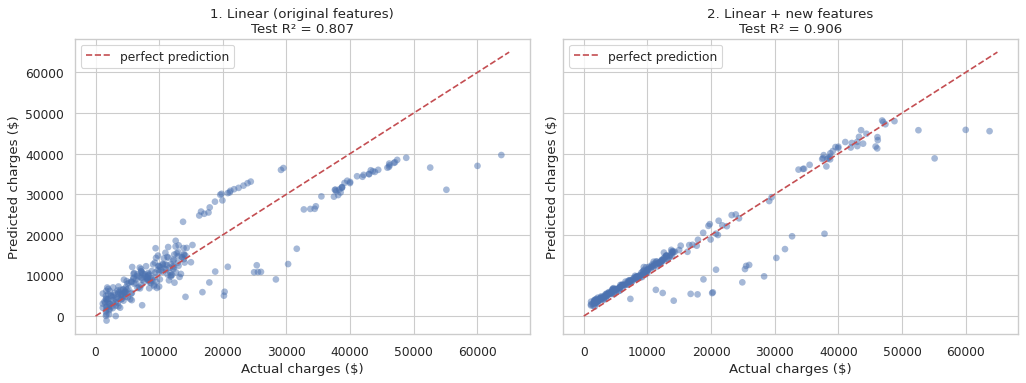

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, r in zip(axes, [results[0], results[1]]):
    ax.scatter(r["_actual"], r["_pred"], alpha=0.5, edgecolor="none")
    lims = [0, 65000]
    ax.plot(lims, lims, "r--", label="perfect prediction")
    ax.set_title(f"{r['Model']}\nTest R² = {r['Test R²']}")
    ax.set_xlabel("Actual charges ($)")
    ax.set_ylabel("Predicted charges ($)")
    ax.legend()
plt.tight_layout()
plt.show()

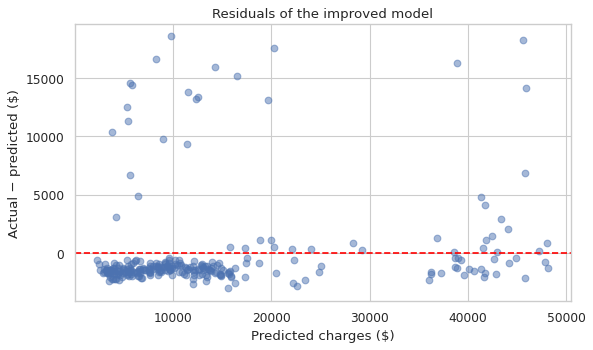

In [12]:
best = results[1]
resid = best["_actual"] - best["_pred"]
plt.figure(figsize=(8, 4.5))
plt.scatter(best["_pred"], resid, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals of the improved model")
plt.xlabel("Predicted charges ($)")
plt.ylabel("Actual − predicted ($)")
plt.show()

With the new features, the points hug the red line much more closely, and the separate "bands" that the original residual plot showed are mostly gone. A few people still cost much more than predicted — probably because of health problems that aren't in this dataset.

## 9. Summary
| Step | What I found |
|---|---|
| Data check | No missing values, 1 duplicate row removed |
| EDA | Smokers pay ~4× more; for smokers, being obese adds ~$20k |
| Original model | CV R² ≈ 0.74 |
| + engineered features | CV R² ≈ 0.86, MAE from about $4,180 to $2,390 |
| Random Forest | CV R² ≈ 0.85 with no extra features |
| Best model | Linear regression with `smoker_obese` + `age²` |

## 10. Reflection
*(Draft — rewrite this in your own words before submitting.)*

This notebook was about predicting how much a person pays for medical insurance using multiple linear regression, based on their age, sex, BMI, children, smoking status and region. The original model explained about 78% of the variation, but its residual plot showed clear patterns, which meant it was missing something. In my version I removed a duplicate row and made plots that showed smoking is the biggest factor, and that BMI only raises costs a lot for people who smoke. I then created new features (`obese`, `smoker_obese` and `age²`), wrote a function to evaluate models with cross-validation, and compared linear regression with a Random Forest. Adding the `smoker_obese` feature made the biggest difference, raising the cross-validated R² from about 0.74 to 0.86. I learned that understanding the data with good plots can improve a model more than just switching to a fancier algorithm. I also learned that cross-validation gives a more honest score than a single train/test split.